In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
import warnings
warnings.filterwarnings('ignore')

df_train = pd.read_csv("data/train_data.csv")
df_test = pd.read_csv("data/test_data.csv")
df_penguins = pd.read_csv("data/penguins_binary_classification.csv")
df_song = pd.read_csv("data/song_data.csv")

# Task 1

In [17]:
target_col = 'age'

feature_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
feature_cols.remove(target_col)

categorical_cols = df_train.select_dtypes(include=['object', 'bool']).columns.tolist()

if categorical_cols:
    df_train = pd.get_dummies(df_train, columns=categorical_cols, drop_first=True)
    df_test = pd.get_dummies(df_test, columns=categorical_cols, drop_first=True)
    for col in df_train.columns:
        if col not in df_test.columns and col != target_col:
            df_test[col] = 0
    for col in df_test.columns:
        if col not in df_train.columns and col != target_col:
            df_train[col] = 0

feature_cols = [col for col in df_train.columns if col != target_col]

for col in feature_cols + [target_col]:
    if df_train[col].isna().sum() > 0:
        df_train[col] = df_train[col].fillna(df_train[col].median())
    if col in df_test.columns and df_test[col].isna().sum() > 0:
        df_test[col] = df_test[col].fillna(df_train[col].median())

X_train = df_train[feature_cols].values
y_train = df_train[target_col].values
X_test = df_test[feature_cols].values

In [18]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_train_pred = model.predict(X_train_scaled)
r2_train = r2_score(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))

print(f"R^2 на обучении: {r2_train:.4f}")
print(f"RMSE на обучении: {rmse_train:.2f}")

R^2 на обучении: 0.9867
RMSE на обучении: 1750.65


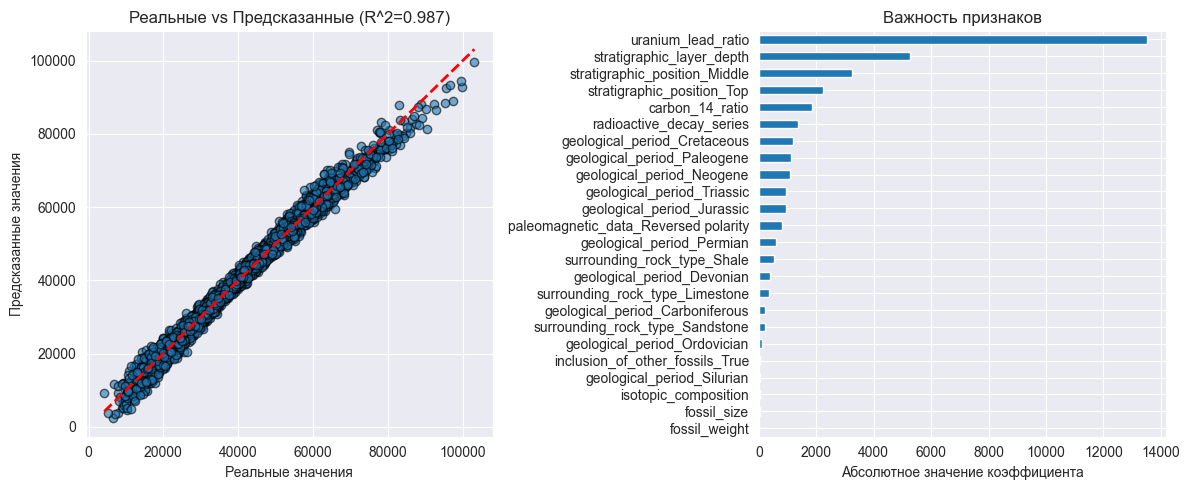

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_train, y_train_pred, alpha=0.6, edgecolors='k')
axes[0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--', lw=2)
axes[0].set_xlabel('Реальные значения')
axes[0].set_ylabel('Предсказанные значения')
axes[0].set_title(f'Реальные vs Предсказанные (R^2={r2_train:.3f})')

coef_series = pd.Series(model.coef_, index=feature_cols)
coef_series.abs().sort_values().plot(kind='barh', ax=axes[1])
axes[1].set_xlabel('Абсолютное значение коэффициента')
axes[1].set_title('Важность признаков')

plt.tight_layout()
plt.show()

In [20]:
test_predictions = model.predict(X_test_scaled)
print(f"Предсказания на тестовых данных: min={test_predictions.min():.2f}, max={test_predictions.max():.2f}, mean={test_predictions.mean():.2f}")

np.random.seed(42)
n_new = 10
new_data = {}

for col in feature_cols:
    mean_val = df_train[col].mean()
    std_val = df_train[col].std()
    new_data[col] = np.random.normal(mean_val, std_val, n_new)
    if col in ['stratigraphic_layer_depth', 'fossil_size', 'fossil_weight',
               'uranium_lead_ratio', 'carbon_14_ratio', 'radioactive_decay_series', 'isotopic_composition']:
        new_data[col] = np.abs(new_data[col])

new_df = pd.DataFrame(new_data)
new_scaled = scaler.transform(new_df.values)
new_predictions = model.predict(new_scaled)

new_df['predicted_age'] = new_predictions
print(new_df.round(2))

Предсказания на тестовых данных: min=849.22, max=90834.85, mean=41190.78
   uranium_lead_ratio  carbon_14_ratio  radioactive_decay_series  \
0                0.61             0.32                      0.95   
1                0.45             0.32                      0.47   
2                0.65             0.49                      0.55   
3                0.88             0.02                      0.12   
4                0.43             0.03                      0.38   
5                0.43             0.30                      0.56   
6                0.89             0.19                      0.20   
7                0.68             0.50                      0.64   
8                0.37             0.22                      0.36   
9                0.63             0.10                      0.45   

   stratigraphic_layer_depth  isotopic_composition  fossil_size  \
0                     100.92                  1.32        82.81   
1                     312.63                

# Task 2

In [21]:
df_penguins['target'] = (df_penguins['species'] == 'Adelie').astype(int)

num_features = df_penguins.select_dtypes(include=[np.number]).columns.tolist()
if 'target' in num_features:
    num_features.remove('target')

for col in num_features:
    if df_penguins[col].isna().sum() > 0:
        df_penguins[col] = df_penguins[col].fillna(df_penguins[col].median())

X = df_penguins[num_features].values
y = df_penguins['target'].values

scaler_peng = StandardScaler()
X_scaled = scaler_peng.fit_transform(X)

split_idx = int(0.8 * len(X_scaled))
X_train, X_test = X_scaled[:split_idx], X_scaled[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

In [22]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Точность модели: {accuracy:.4f}")

cm = confusion_matrix(y_test, y_pred)
print("Матрица ошибок:")
if cm.shape == (1, 1):
    print(f"  [[{cm[0][0]}]]")
    print("  (В тестовой выборке представлен только один класс)")
else:
    print(pd.DataFrame(cm, columns=['Pred 0', 'Pred 1'], index=['True 0', 'True 1']))

Точность модели: 1.0000
Матрица ошибок:
  [[55]]
  (В тестовой выборке представлен только один класс)


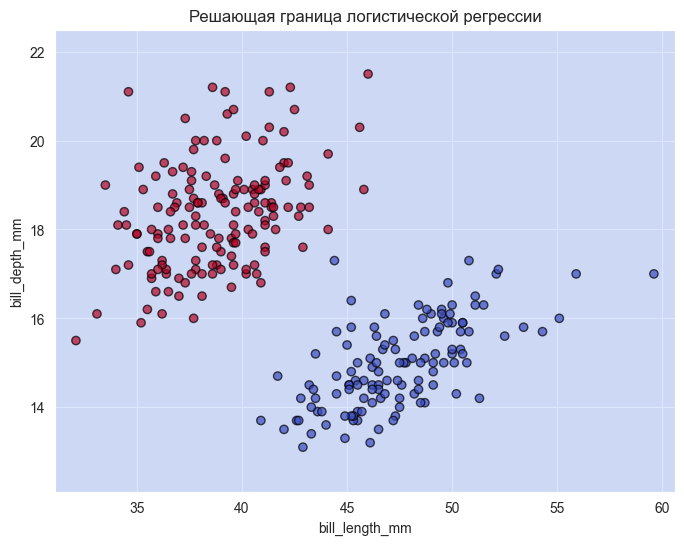

In [23]:
feature1, feature2 = num_features[0], num_features[1]

x_min, x_max = df_penguins[feature1].min() - 1, df_penguins[feature1].max() + 1
y_min, y_max = df_penguins[feature2].min() - 1, df_penguins[feature2].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

grid_input = np.c_[xx.ravel(), yy.ravel()]
for _ in range(len(num_features) - 2):
    grid_input = np.c_[grid_input, np.zeros(grid_input.shape[0])]
grid_scaled = scaler_peng.transform(grid_input)

Z = log_reg.predict(grid_scaled).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(df_penguins[feature1], df_penguins[feature2], c=df_penguins['target'],
            cmap='coolwarm', edgecolors='k', alpha=0.7)
plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title('Решающая граница логистической регрессии')
plt.show()

# Task ****

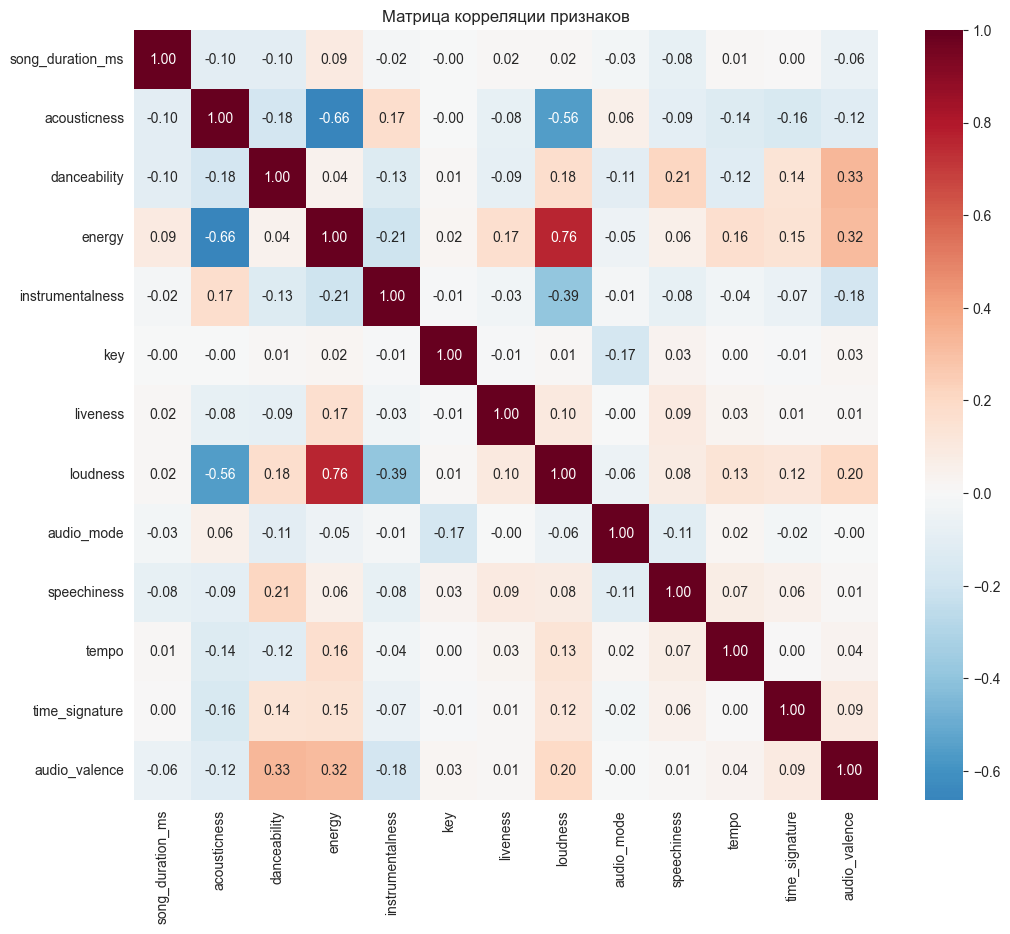

             feature        VIF
11    time_signature  88.901818
3             energy  30.732653
2       danceability  21.625450
10             tempo  18.285176
0   song_duration_ms  14.265089
7           loudness  11.940959
12     audio_valence   7.716693
5                key   3.208983
1       acousticness   3.177762
8         audio_mode   2.805870
6           liveness   2.681362
9        speechiness   2.154095
4   instrumentalness   1.400073


In [24]:
target = 'song_popularity'
feature_cols = df_song.select_dtypes(include=[np.number]).columns.tolist()
feature_cols.remove(target)

for col in feature_cols + [target]:
    if df_song[col].isna().sum() > 0:
        df_song[col] = df_song[col].fillna(df_song[col].median())

corr_matrix = df_song[feature_cols].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.title('Матрица корреляции признаков')
plt.show()

X_song = df_song[feature_cols].values
vif_data = pd.DataFrame({
    'feature': feature_cols,
    'VIF': [variance_inflation_factor(X_song, i) for i in range(len(feature_cols))]
})
print(vif_data.sort_values('VIF', ascending=False))

In [25]:
X = df_song[feature_cols].values
y = df_song[target].values

scaler_song = StandardScaler()
X_scaled = scaler_song.fit_transform(X)

split_idx = int(0.8 * len(X_scaled))
X_train, X_test = X_scaled[:split_idx], X_scaled[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# Линейная регрессия
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

# Ридж-регрессия
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_test)

# Случайный лес
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

            Модель      R^2      RMSE       MAE
Линейная регрессия 0.045602 21.997788 17.508486
    Ридж-регрессия 0.045599 21.997825 17.508531
     Случайный лес 0.452778 16.656964 11.539779


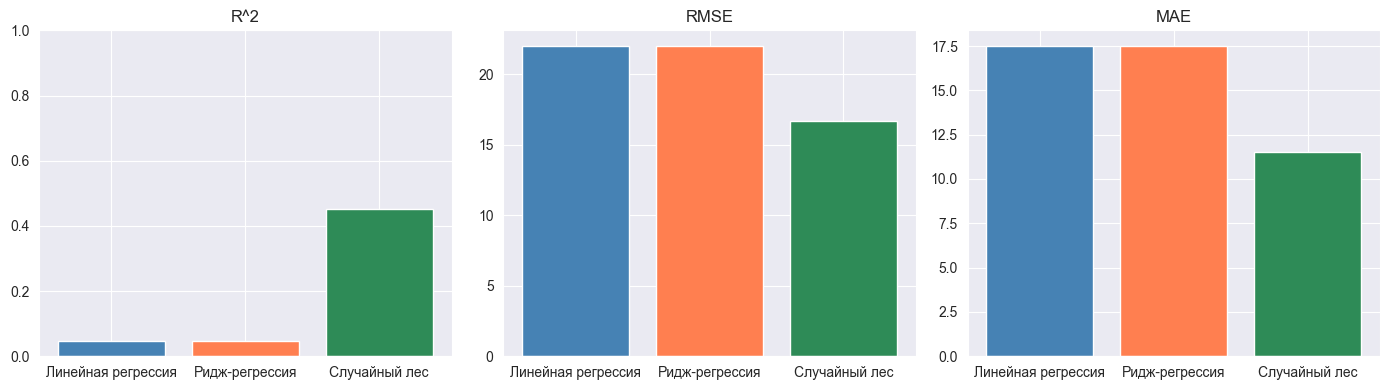

Лучшая модель: Случайный лес (R^2 = 0.4528)


In [26]:
results = pd.DataFrame({
    'Модель': ['Линейная регрессия', 'Ридж-регрессия', 'Случайный лес'],
    'R^2': [r2_score(y_test, y_pred_lr), r2_score(y_test, y_pred_ridge), r2_score(y_test, y_pred_rf)],
    'RMSE': [np.sqrt(mean_squared_error(y_test, y_pred_lr)),
             np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
             np.sqrt(mean_squared_error(y_test, y_pred_rf))],
    'MAE': [mean_absolute_error(y_test, y_pred_lr),
            mean_absolute_error(y_test, y_pred_ridge),
            mean_absolute_error(y_test, y_pred_rf)]
})

print(results.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
models = results['Модель']
colors = ['steelblue', 'coral', 'seagreen']

axes[0].bar(models, results['R^2'], color=colors)
axes[0].set_title('R^2')
axes[0].set_ylim(0, 1)

axes[1].bar(models, results['RMSE'], color=colors)
axes[1].set_title('RMSE')

axes[2].bar(models, results['MAE'], color=colors)
axes[2].set_title('MAE')

plt.tight_layout()
plt.show()

best_idx = results['R^2'].idxmax()
print(f"Лучшая модель: {results.loc[best_idx, 'Модель']} (R^2 = {results.loc[best_idx, 'R^2']:.4f})")